# Example 8.2 — Particle Swarm Synthesis (PSO)
**Book:** Four-Bar Linkage Synthesis with GA and Neural Networks  
**Chapter 8** | Google Colab

## Base functions

In [6]:
from numpy import *
import builtins


def fourbar_coupler(a, b, c, d, th2, p=35.0, delta=pi / 5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)
    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    return a * cos(th2) + p * cos(th3 + delta), a * sin(th2) + p * sin(th3 + delta)


def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px) ** 2 + (Cy[m, None] - Py) ** 2)
    return builtins.max(D.min(0).max(), D.min(1).max())


t = linspace(0, 2 * pi, 20)
Px = 45 + 22 * cos(t)
Py = 25 + 18 * sin(t)
th2v = linspace(0, 2 * pi, 72)
D_F = 85.0


def fitness(p):
    return hausdorff(*fourbar_coupler(p[0], p[1], p[2], D_F, th2v), Px, Py)

## PSO algorithm

In [9]:
random.seed(11)
N = 20
N_ITER = 25
w = 0.7
c1 = 1.5
c2 = 1.5

LB = array([10.0, 10.0, 10.0])
UB = array([80.0, 60.0, 80.0])

pos = LB + random.rand(N, 3) * (UB - LB)
vel = zeros((N, 3))
pbest = pos.copy()
pbest_f = array([fitness(p) for p in pos])
gbest = pbest[argmin(pbest_f)].copy()

hist = [fitness(gbest)]
all_pos = [pos.copy()]

for _ in range(N_ITER):
    r1 = random.rand(N, 3)
    r2 = random.rand(N, 3)

    vel = w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos)
    pos = clip(pos + vel, LB, UB)

    f_new = array([fitness(p) for p in pos])
    better = f_new < pbest_f
    pbest[better] = pos[better]
    pbest_f[better] = f_new[better]

    gbest = pbest[argmin(pbest_f)].copy()

    hist.append(fitness(gbest))
    all_pos.append(pos.copy())

print(f"Initial error: {hist[0]:.2f} mm")
print(f"Final error  : {hist[-1]:.2f} mm")
print(f"Reduction    : {100 * (hist[0] - hist[-1]) / hist[0]:.1f}%")
print(f"Best solution: a={gbest[0]:.2f}, b={gbest[1]:.2f}, c={gbest[2]:.2f}")

Initial error: 22.28 mm
Final error  : 10.70 mm
Reduction    : 52.0%
Best solution: a=40.20, b=10.00, c=44.30


## Display

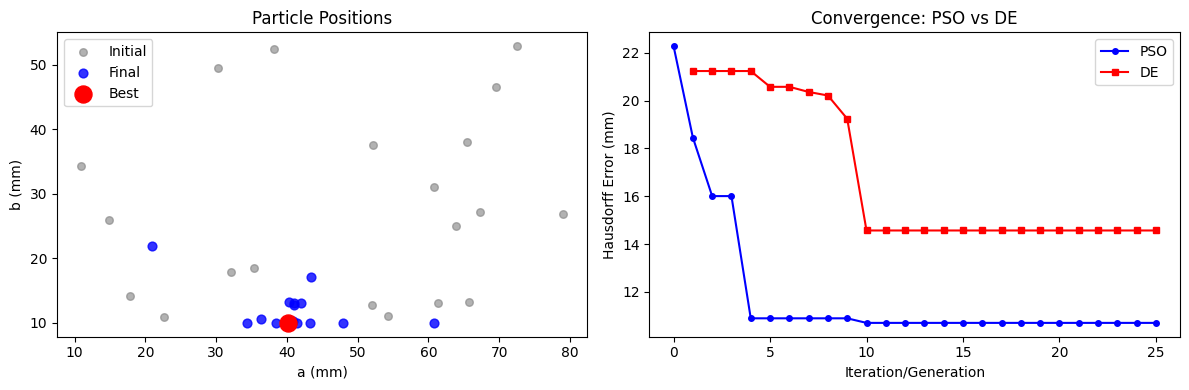

In [10]:
import matplotlib.pyplot as plt
import builtins

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Particle trajectories in a-b plane
pos0 = array(all_pos[0])
posf = array(all_pos[-1])

axes[0].scatter(pos0[:, 0], pos0[:, 1], s=30, alpha=0.6, label='Initial', color='gray')
axes[0].scatter(posf[:, 0], posf[:, 1], s=40, alpha=0.8, label='Final', color='blue')
axes[0].scatter([gbest[0]], [gbest[1]], s=150, color='red', zorder=5, label='Best')
axes[0].set_xlabel('a (mm)')
axes[0].set_ylabel('b (mm)')
axes[0].set_title('Particle Positions')
axes[0].legend()

# DE vs PSO Convergence
random.seed(3)
N_POP = 15
N_GEN = 25
F = 0.8
CR = 0.9

pop_de = LB + random.rand(N_POP, 3) * (UB - LB)
hist_de = []

for gen in range(N_GEN):
    for i in range(N_POP):
        idxs = list(range(N_POP))
        idxs.remove(i)
        a_, b_, c_ = pop_de[random.choice(idxs, 3, replace=False)]
        mut = clip(a_ + F * (b_ - c_), LB, UB)
        cross = random.rand(3) < CR
        if not cross.any():
            cross[random.randint(3)] = True
        trial = where(cross, mut, pop_de[i])
        if fitness(trial) < fitness(pop_de[i]):
            pop_de[i] = trial
    hist_de.append(fitness(builtins.min(pop_de, key=fitness)))

gen_range = arange(len(hist))
axes[1].plot(gen_range, hist, 'b-o', ms=4, label='PSO')
axes[1].plot(arange(1, len(hist_de) + 1), hist_de, 'r-s', ms=4, label='DE')
axes[1].set_xlabel('Iteration/Generation')
axes[1].set_ylabel('Hausdorff Error (mm)')
axes[1].set_title('Convergence: PSO vs DE')
axes[1].legend()

plt.tight_layout()
plt.show()